# GIF and time-smoothing inspector

Segments one glacier's full time series, writes the GIF that `glacierview infer` would (the smoothed
true-colour scene with the predicted mask over it), and shows inline images for judging how well the
time smoothing works:

- **Frames:** scenes before and after smoothing, side by side, with the predicted probability at each
  smoothing strength. Missing pixels (fill, or outside a scene's footprint) show magenta in the
  unsmoothed row. There's one spread across the series and one run of consecutive dates.
- **Pixel series:** green, SWIR and NDSI through time at three pixels (glacier core, glacier edge,
  off-glacier), unsmoothed as dots and smoothed as lines.
- **Area series:** the glacier's area per scene at each smoothing strength, with a scene-to-scene
  noise figure for each.

**Time smoothing** is a Gaussian along time only: each pixel against itself on neighbouring dates.
`SIGMA` is in *frames* (scenes), not days, and `config.TIME_SMOOTHING_SIGMA` (20) is what the pipeline
uses. `SIGMA = 0` turns it off. `COMPARE_SIGMAS` adds more strengths to the frame, pixel and area
comparisons, at one more model pass each.

## Inputs
- A glacier's scenes and DEM: by default the committed sample (`data/sample/inference`), where only
  Trient (`G007026E45991N`) has a full series. Set `USE_SAMPLE = False` for `config.DATA_ROOT`'s
  landing zone.
- A checkpoint: `CHECKPOINT`, by default the published one from Hugging Face. It was trained on
  `PREPROCESSING = "published"`; `"current"` needs a retrained model (see `glacierview.preprocess`).
- Optionally the quality filter, `config.filtered_inference_path()` (`USE_FILTER`).

## Outputs
- `config.outputs_dir()/gifs/<glims_id>_<preprocessing>_sigma<SIGMA>.gif` (gitignored), built from
  scratch frames in `config.outputs_dir()/tmp/gif_smoothing/`.
- Inline figures. `SHOW_GIF_INLINE = True` embeds the GIF too, which can add tens of MB to the
  notebook, so clear that output before committing.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from glacierview import config, preprocess, rasters
from glacierview.inference import predict, render
from glacierview.models import load_checkpoint

# `render` switches matplotlib to the headless Agg backend on import; switch back so figures show.
%matplotlib inline

# True: the committed sample, where only Trient has a full series. False: config.DATA_ROOT.
USE_SAMPLE = True
GLIMS_ID = None              # a GLIMS ID, or None for a random glacier with >= MIN_SCENES scenes
MIN_SCENES = 150
SEED = None                  # set for a repeatable random pick
PREPROCESSING = "current"    # "published" matches the published checkpoint
CHECKPOINT = "GlacierView/glacierview-unet"
USE_FILTER = True           # only the scenes listed in config.filtered_inference_path()

SIGMA = config.TIME_SMOOTHING_SIGMA  # time smoothing, in frames; 0 turns it off
COMPARE_SIGMAS = [3, 4]      # also segmented at these, for comparison
N_FRAMES = 6                 # frames per row in the frame grids
PIXEL_YEARS = 4              # pixel series: years shown around mid-series; None for all of it
GIF_STRIDE = 1              # every Nth scene goes into the GIF
SHOW_GIF_INLINE = False      # embeds the GIF in the notebook (large)
GAMMA = 0.7                  # display brightening only

root = config.SAMPLE_INFERENCE_ROOT if USE_SAMPLE else None
label = config.INFERENCE_DATA_LABEL
filter_csv = config.filtered_inference_path(label) if USE_FILTER else None
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
sigmas = list(dict.fromkeys([SIGMA, *COMPARE_SIGMAS]))  # SIGMA first, no repeats
# One colour per smoothed sigma, from the shared style; unsmoothed values are drawn as dots.
with plt.style.context(config.mpl_style()):
    style_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
line_colors = dict(zip([s for s in sigmas if s > 0], style_colors * 3, strict=False))
SATELLITE_COLORS = {"L5": "tab:orange", "L7": "tab:purple", "L8": "tab:green"}
RGB = [config.COMMON_BANDS.index(b) for b in ("red", "green", "blue")]

## Pick a glacier

In [2]:
landsat = config.landsat_dir(label, root=root)
if GLIMS_ID:
    glims_id = GLIMS_ID
else:
    if filter_csv:
        listed = pd.read_csv(filter_csv)["glims_id"].value_counts()
        counts = {g: n for g, n in listed.items() if (landsat / g).is_dir()}
    else:
        counts = {d.name: len(rasters.list_scenes(d, since=config.FIRST_VALID_DATE))
                  for d in sorted(landsat.iterdir()) if d.is_dir() and not d.name.startswith(".")}
    candidates = sorted(g for g, n in counts.items() if n >= MIN_SCENES)
    if not candidates:
        raise RuntimeError(f"no glacier under {landsat} has {MIN_SCENES} or more scenes")
    glims_id = random.Random(SEED).choice(candidates)
    print(f"{len(candidates)} glaciers have >= {MIN_SCENES} scenes; picked {glims_id}")

glacier_dir = config.glacier_dir("G007026E45991N", label, root)
dem_path = config.dem_path("G007026E45991N", label, root)

9 glaciers have >= 150 scenes; picked G290163E33530S


## Segment it at each smoothing strength

`read_stack` gives the unsmoothed stack. Under `"current"` its missing pixels are NaN, and the share
missing is printed per satellite. Each sigma is then smoothed, segmented and measured the way
`glacierview infer` does it.

In [3]:
model = load_checkpoint(CHECKPOINT, device)
raw, file_names, sizes = predict.read_stack(glacier_dir, dem_path, filter_csv, PREPROCESSING)
dates = pd.DatetimeIndex(predict.dates_from_filenames(file_names))
satellites = np.array([f.split("_")[2] for f in file_names])
print(f"{glims_id}: {len(file_names)} scenes, {dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d}")
missing = pd.Series(np.isnan(raw[..., :-1]).mean(axis=(1, 2, 3)), index=satellites)
print("share of band pixels missing, by satellite:")
print(missing.groupby(level=0).mean().map("{:.1%}".format).to_string())


def segment(sigma):
    """Smooth, segment and measure the series at one sigma."""
    smoothed, missing = predict.smooth_stack(raw, PREPROCESSING, sigma, with_missing=True)
    probs = predict.predict_probabilities(
        model, predict.model_inputs(smoothed, PREPROCESSING), device
    )
    areas = predict.areas_km2(predict.AREA_VARIANTS["binary"](probs), sizes)
    return smoothed, missing, probs[:, 0].numpy(), np.array(areas)


smoothed, missing, probs, areas = segment(SIGMA)
runs = {SIGMA: {"probs": probs, "areas": areas}}

# Pixels to follow through time, picked from the main run's mean probability.
mean_prob = probs.mean(axis=0)
pixels = {
    "glacier core": np.unravel_index(mean_prob.argmax(), mean_prob.shape),
    "glacier edge": np.unravel_index(np.abs(mean_prob - 0.5).argmin(), mean_prob.shape),
    "off glacier": np.unravel_index(mean_prob.argmin(), mean_prob.shape),
}
runs[SIGMA]["pixels"] = {name: smoothed[:, r, c] for name, (r, c) in pixels.items()}

for sigma in sigmas[1:]:
    other, _, other_probs, other_areas = segment(sigma)
    runs[sigma] = {
        "probs": other_probs,
        "areas": other_areas,
        "pixels": {name: other[:, r, c] for name, (r, c) in pixels.items()},
    }
    del other  # a full series is gigabytes

for sigma, run in runs.items():
    print(f"sigma {sigma:>4}: {run['areas'][0]:.2f} -> {run['areas'][-1]:.2f} km^2")

G290163E33530S: 62 scenes, 1988-05-06 to 2023-10-07
share of band pixels missing, by satellite:
L5    0.8%
L7    4.3%
L8    0.5%
sigma    2: 6.20 -> 5.73 km^2
sigma    3: 6.16 -> 5.78 km^2
sigma    4: 6.13 -> 5.79 km^2


The same rendering as `glacierview areas`, every `GIF_STRIDE`th scene: the smoothed true-colour
scene, the mask over it, the GLIMS outline as ground truth (`"current"` only) and the DEM, then NDSI,
SWIR and thermal. Each frame's title has that scene's area at `SIGMA`.

In [4]:
gif_path = render.write_gif(
    gif_path=config.outputs_dir() / "gifs" / f"{glims_id}_{PREPROCESSING}_sigma{SIGMA}.gif",
    scratch_dir=config.outputs_dir() / "tmp" / "gif_smoothing",
    images=smoothed,
    probabilities=torch.from_numpy(probs[:, np.newaxis]),
    file_names=file_names,
    stride=GIF_STRIDE,
    overlay=True,
    ground_truth=(render.ground_truth_mask(glims_id, dem_path)
                  if PREPROCESSING == "current" else None),
    areas=areas,
    missing=missing,
    scenes_dir=glacier_dir,
    grid=rasters.reference_grid(dem_path) if PREPROCESSING == "current" else None,
)
print(gif_path)
if SHOW_GIF_INLINE:
    display(Image(filename=str(gif_path)))

/Users/mattw/Desktop/projects/GlacierView/src/segmentation/gifs/G290163E33530S_current_sigma2.gif


## Frames before and after smoothing

Each column is one scene. The rows are:
1. The scene unsmoothed. Missing pixels are magenta.
2. The scene smoothed at `SIGMA`.
3. The predicted glacier probability at each sigma, with the 0.5 contour in white.

Things to look for:
- **Gaps:** is a Landsat 7 stripe or a cloud gap filled cleanly?
- **Ghosting:** does a fresh-snow scene, or a missing patch, smear into its neighbours?
- **Edges:** does the edge stay sharp as sigma grows?

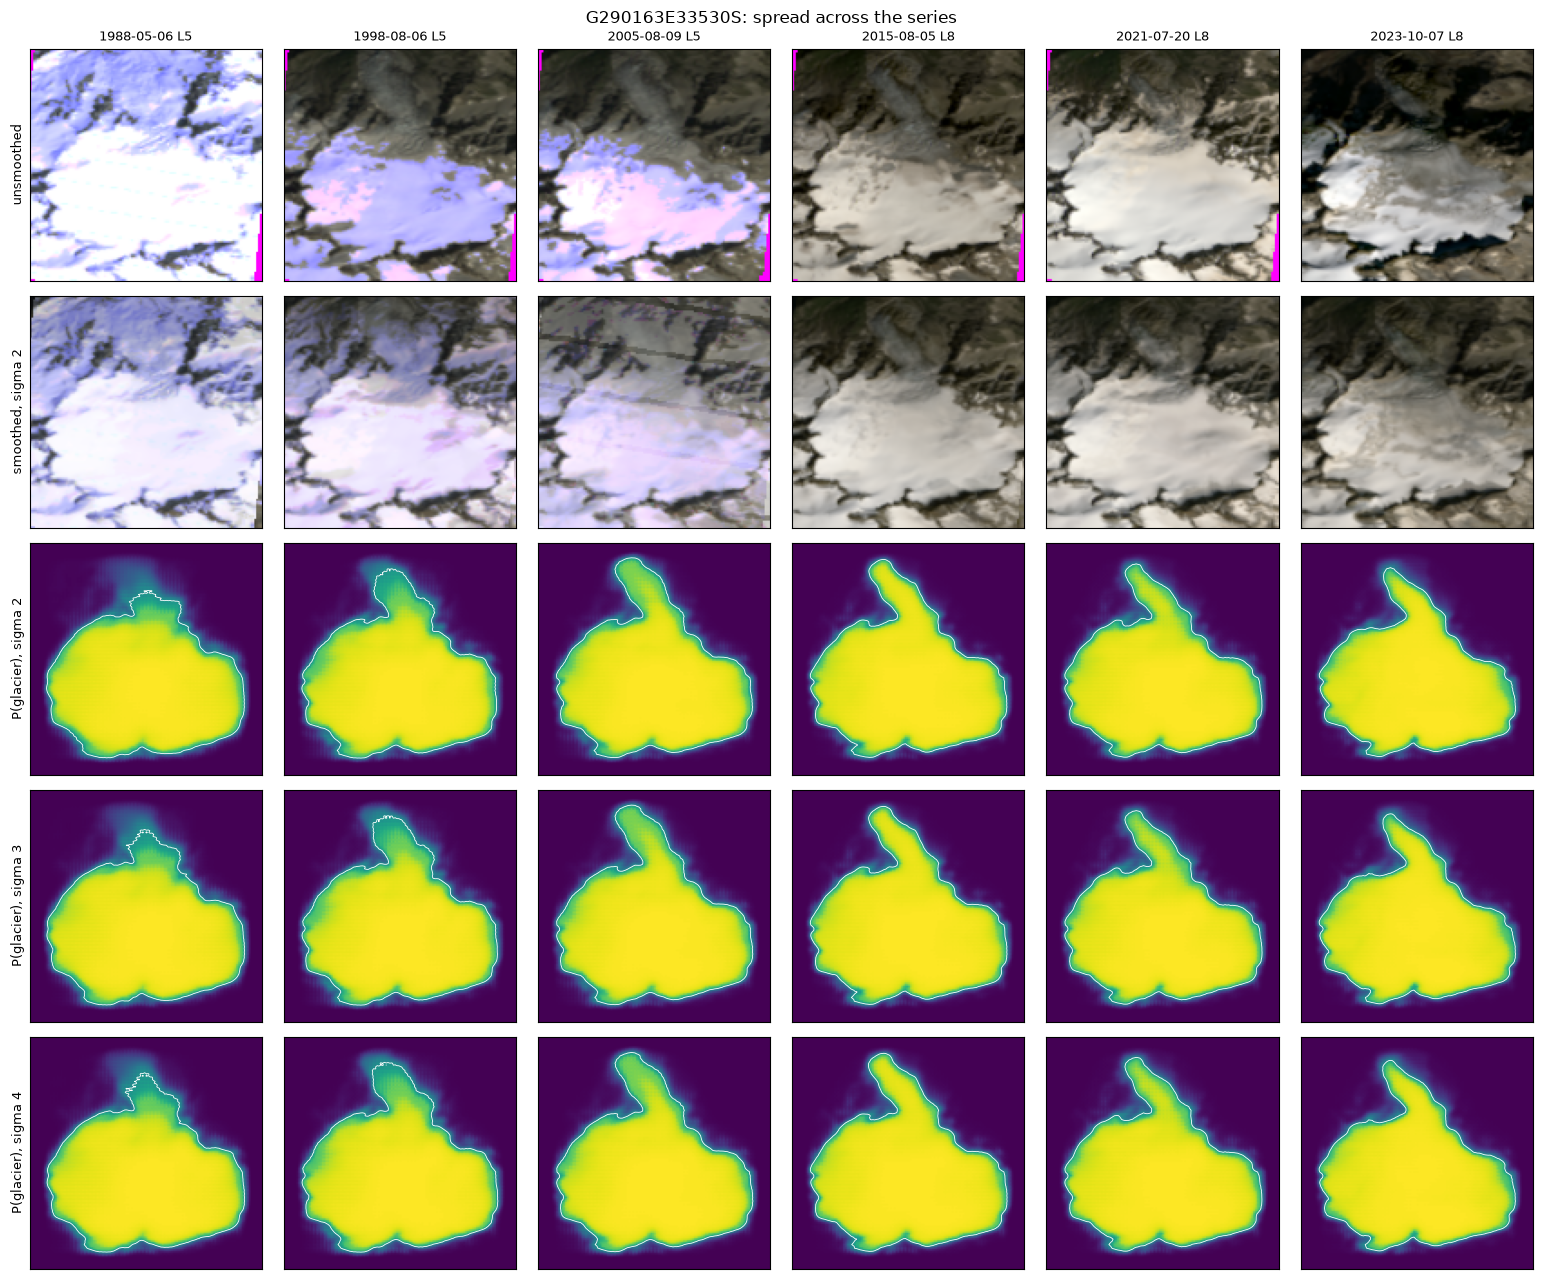

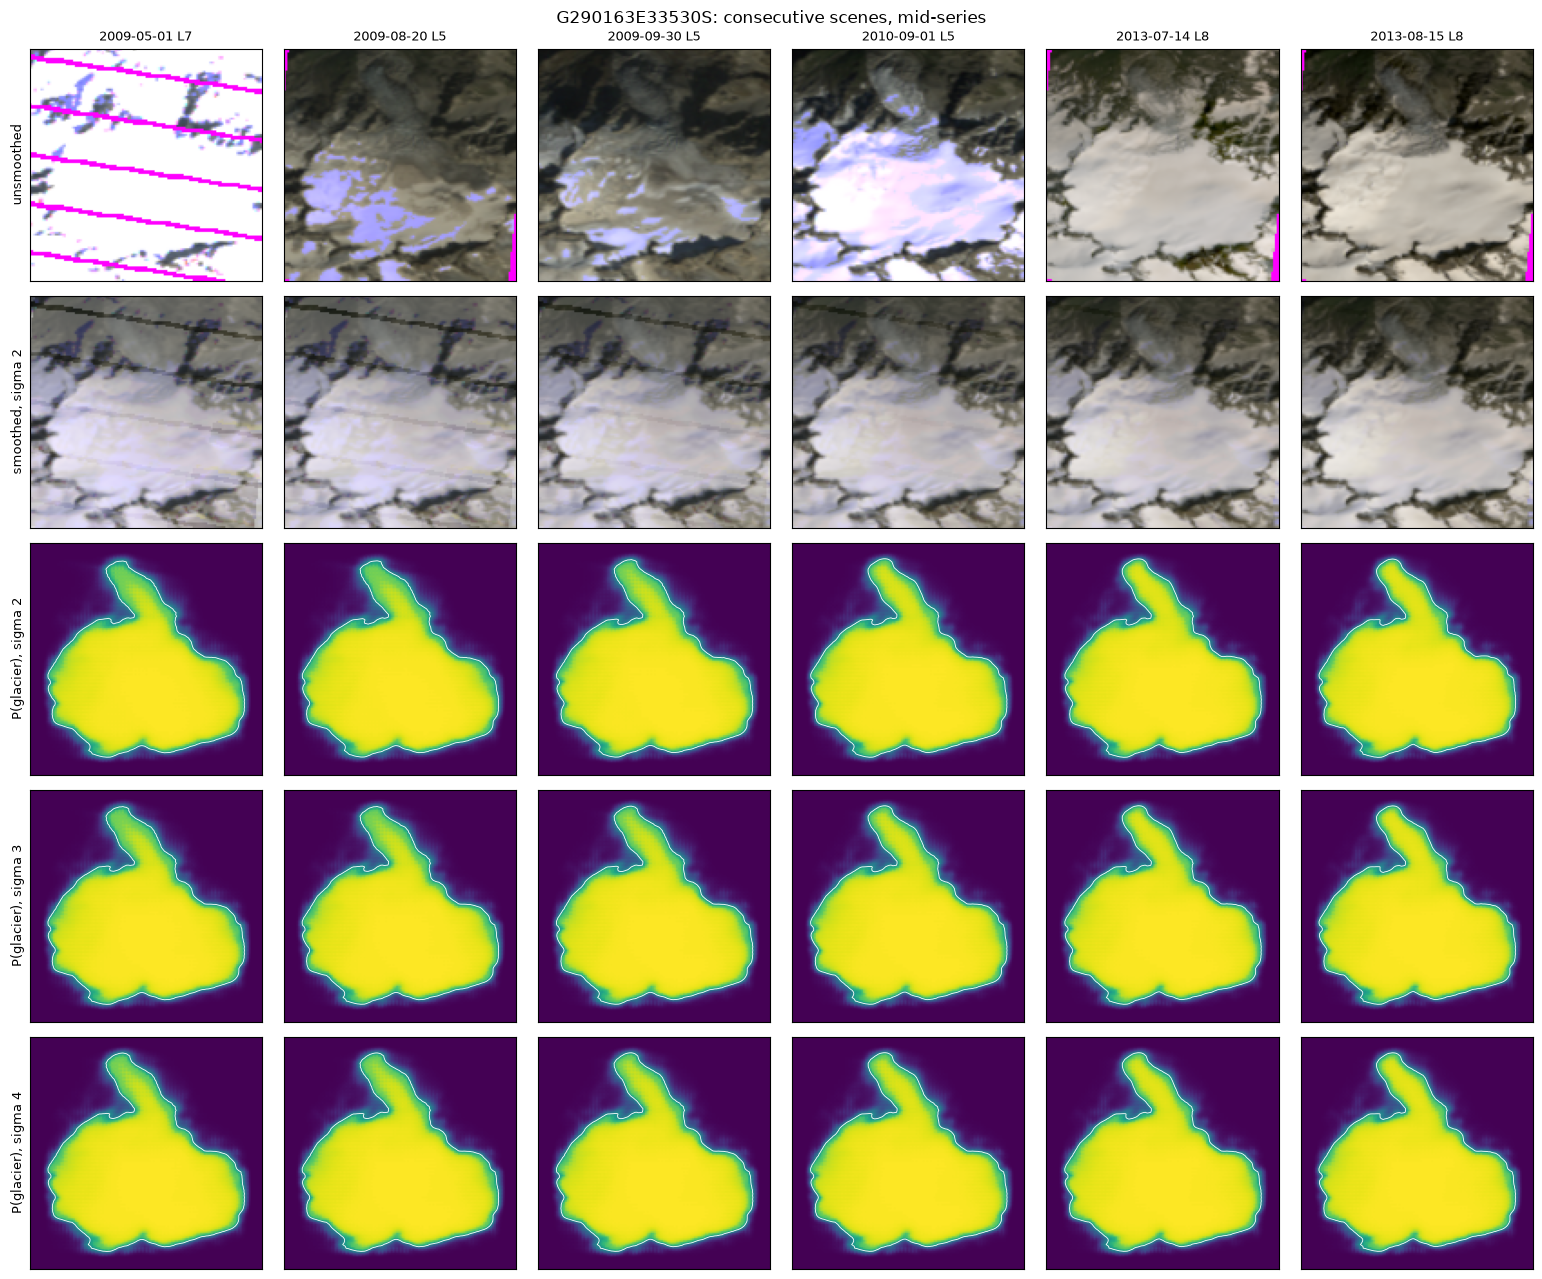

In [5]:
def display_rgb(frame):
    """True colour for display, gamma-brightened, with missing pixels magenta."""
    image = frame[..., RGB]
    missing = np.isnan(image).any(axis=-1)
    image = np.clip(np.nan_to_num(image), 0, 1) ** GAMMA
    image[missing] = (1, 0, 1)
    return image


def frame_grid(indices, title):
    rows = 2 + len(runs)
    fig, axs = plt.subplots(rows, len(indices), figsize=(2.6 * len(indices), 2.6 * rows),
                            squeeze=False)
    fig.suptitle(f"{glims_id}: {title}")
    for col, i in enumerate(indices):
        axs[0, col].set_title(f"{dates[i]:%Y-%m-%d} {satellites[i]}", fontsize=9)
        axs[0, col].imshow(display_rgb(raw[i]))
        axs[1, col].imshow(display_rgb(smoothed[i]))
        for row, run in enumerate(runs.values(), start=2):
            axs[row, col].imshow(run["probs"][i], vmin=0, vmax=1, cmap="viridis")
            axs[row, col].contour(run["probs"][i], levels=[0.5], colors="white", linewidths=0.6)
    labels = ["unsmoothed", f"smoothed, sigma {SIGMA}", *(f"P(glacier), sigma {s}" for s in runs)]
    for ax, text in zip(axs[:, 0], labels, strict=True):
        ax.set_ylabel(text, fontsize=9)
    for ax in axs.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    plt.show()


n = len(file_names)
frame_grid(np.linspace(0, n - 1, min(N_FRAMES, n)).astype(int), "spread across the series")
start = max(0, n // 2 - N_FRAMES // 2)
frame_grid(range(start, min(n, start + N_FRAMES)), "consecutive scenes, mid-series")

## Pixel series

Three pixels followed through time: green, SWIR and NDSI (high for snow and ice). Unsmoothed values
are dots, so gaps show where a pixel was missing. Each line is one sigma above 0. A good smooth
follows the seasonal and long-term level without chasing single-scene spikes. The map marks the
three pixels on the main run's mean probability. `PIXEL_YEARS` sets the window shown.

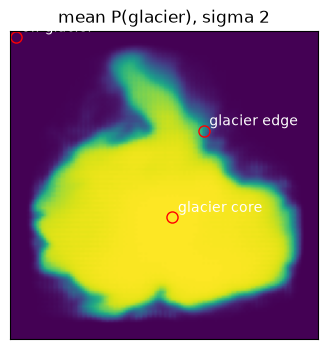

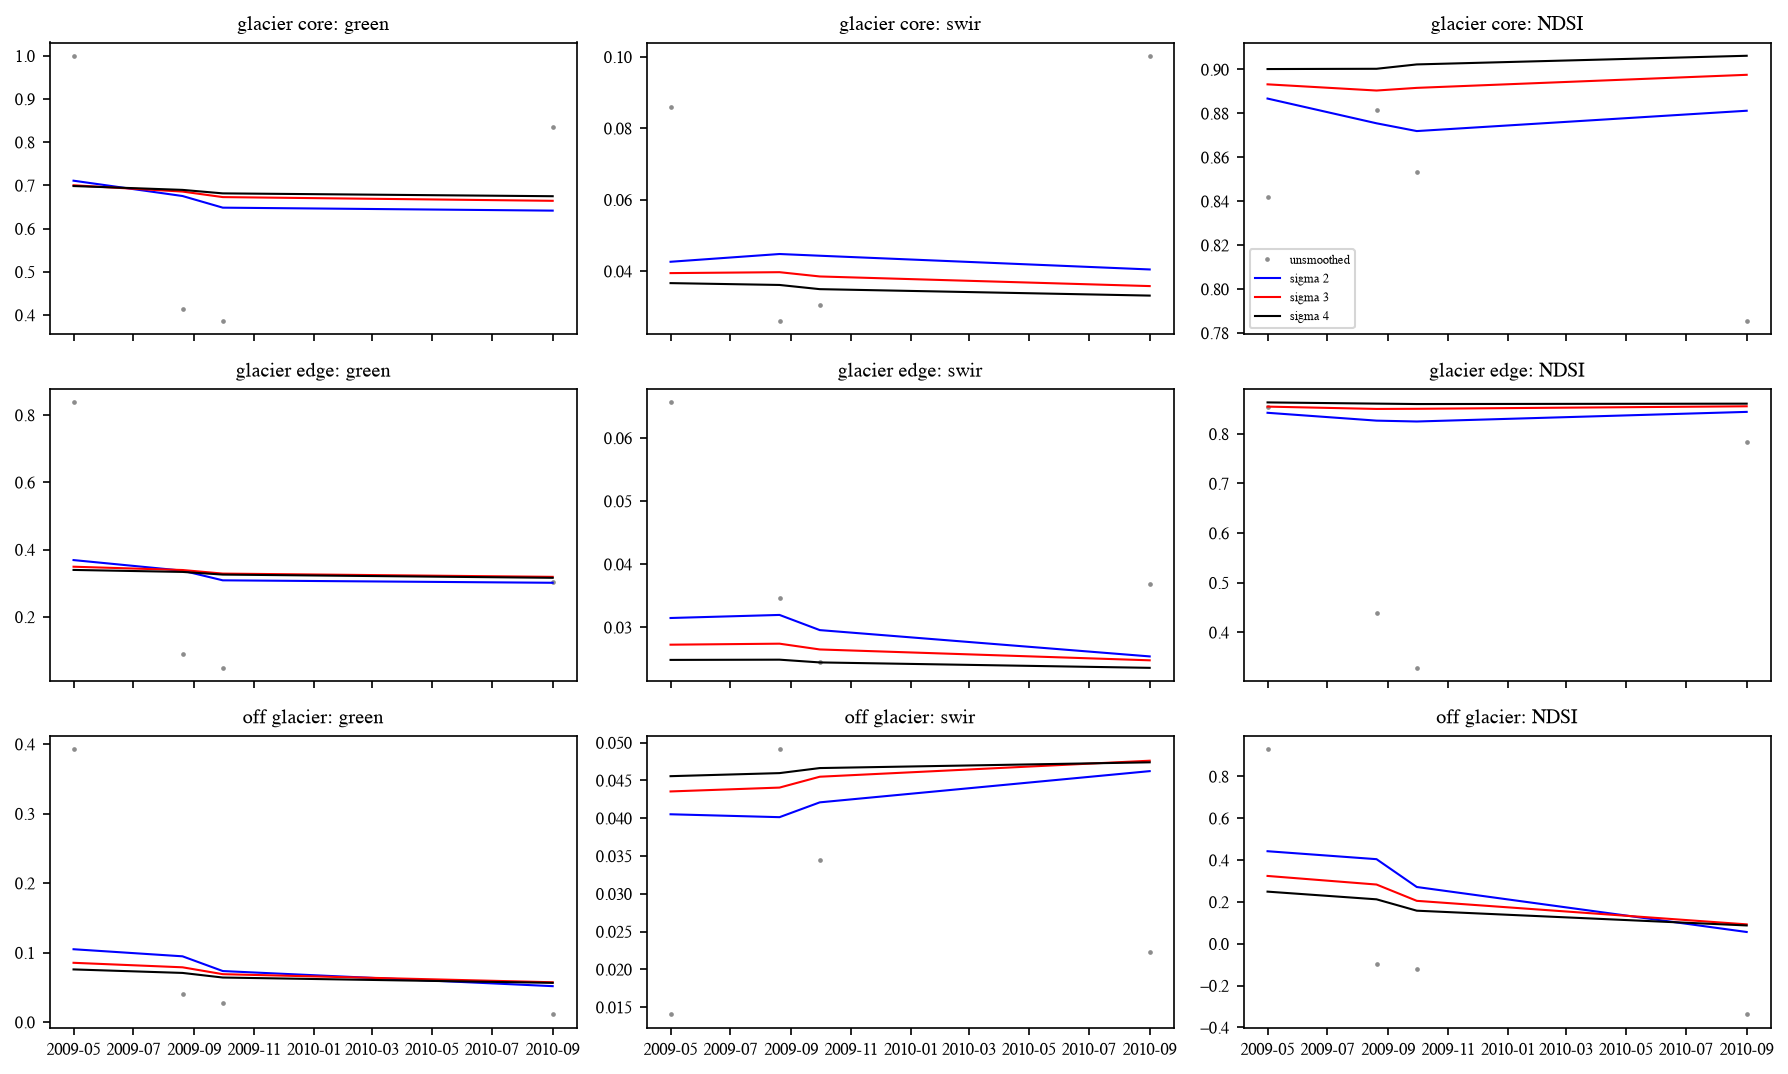

In [6]:
legacy = PREPROCESSING == "published"


def ndsi(series):
    """NDSI of an (N, C) pixel series, through the pipeline's own formula."""
    t = torch.from_numpy(np.ascontiguousarray(series, dtype=np.float64))[:, :, None, None]
    return preprocess.add_spectral_indices(t, legacy=legacy)[:, 1, 0, 0].numpy()


green, swir = config.COMMON_BANDS.index("green"), config.COMMON_BANDS.index("swir")
channels = {"green": lambda s: s[:, green], "swir": lambda s: s[:, swir], "NDSI": ndsi}

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(mean_prob, vmin=0, vmax=1, cmap="viridis")
for name, (r, c) in pixels.items():
    ax.plot(c, r, "o", markersize=8, markerfacecolor="none", markeredgecolor="red")
    ax.annotate(name, (c, r), xytext=(4, 4), textcoords="offset points", color="white")
ax.set_title(f"mean P(glacier), sigma {SIGMA}")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

if PIXEL_YEARS:
    middle = dates[len(dates) // 2]
    half = pd.DateOffset(months=int(6 * PIXEL_YEARS))
    shown = (dates >= middle - half) & (dates <= middle + half)
else:
    shown = np.ones(len(dates), dtype=bool)

with plt.style.context([config.mpl_style(), {"figure.dpi": 150}]):
    fig, axs = plt.subplots(len(pixels), len(channels), figsize=(12, 2.4 * len(pixels)),
                            sharex=True, squeeze=False)
    for row, (name, (r, c)) in enumerate(pixels.items()):
        for col, (channel, get) in enumerate(channels.items()):
            ax = axs[row, col]
            ax.plot(dates[shown], get(raw[shown, r, c]), ".", color="0.55", markersize=2.5,
                    linestyle="none", label="unsmoothed")
            for sigma, run in runs.items():
                if sigma > 0:
                    ax.plot(dates[shown], get(run["pixels"][name][shown]), color=line_colors[sigma],
                            linestyle="-", label=f"sigma {sigma}")
            ax.set_title(f"{name}: {channel}")
    axs[0, -1].legend(fontsize=6)
    fig.tight_layout()
    plt.show()

## Area series

Area per scene at each sigma, in km² on the 30 m grid. "Noise" is the median change in area from one
scene to the next. Smoothing should bring it down without flattening the trend or shifting the turning
points.

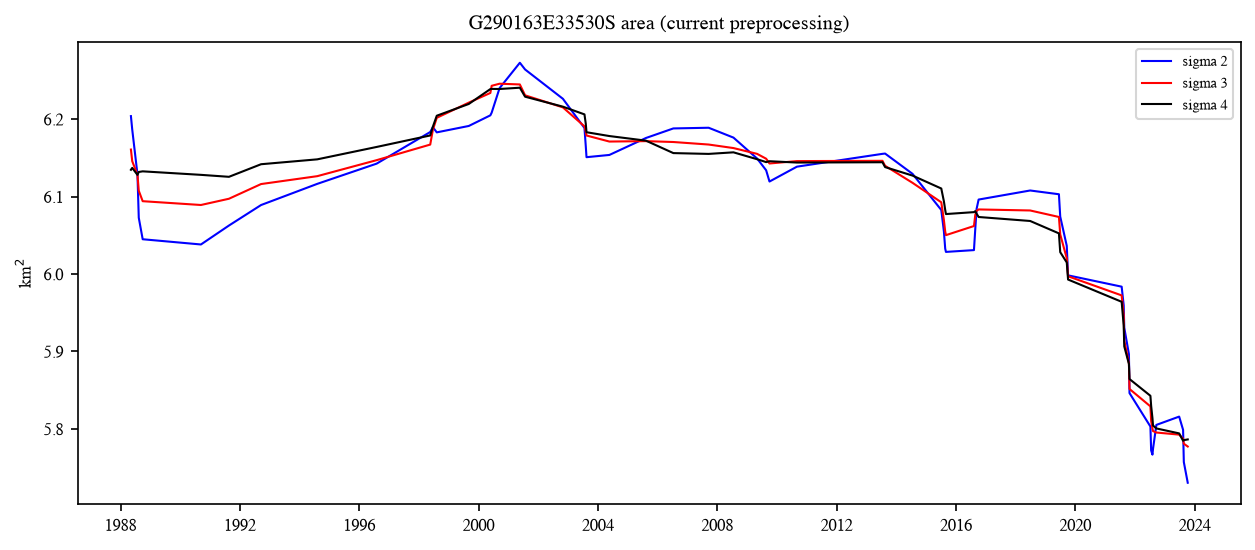

sigma,2,3,4
first scene (km^2),6.204,6.161,6.135
last scene (km^2),5.730,5.777,5.786
noise: median |scene-to-scene change| (km^2),0.023,0.010,0.010


In [7]:
with plt.style.context([config.mpl_style(), {"figure.dpi": 150}]):
    fig, ax = plt.subplots(figsize=(10, 4))
    if 0 in runs:  # unsmoothed, as dots by satellite, drawn first so the lines sit on top
        for sat in np.unique(satellites):
            at = satellites == sat
            ax.plot(dates[at], runs[0]["areas"][at], ".", color=SATELLITE_COLORS.get(sat, "0.5"),
                    alpha=0.5, markersize=2.5, linestyle="none", label=f"sigma 0, {sat}")
    for sigma, run in runs.items():
        if sigma > 0:
            ax.plot(dates, run["areas"], color=line_colors[sigma], linestyle="-",
                    label=f"sigma {sigma}")
    ax.set_ylabel("km$^2$")
    ax.set_title(f"{glims_id} area ({PREPROCESSING} preprocessing)")
    ax.legend(fontsize=7)
    plt.show()

pd.DataFrame({
    sigma: {
        "first scene (km^2)": run["areas"][0],
        "last scene (km^2)": run["areas"][-1],
        "noise: median |scene-to-scene change| (km^2)": np.median(np.abs(np.diff(run["areas"]))),
    }
    for sigma, run in runs.items()
}).rename_axis(columns="sigma").round(3)